In [41]:
import torch
from anemone.experiment import *
from anemone.forwards import *

def check_halfspace_circle_center(ForwardMaker, radius = 10., rtol=3e-2):
    from anemone.experiment import Loop, Receiver
    from anemone.physics import hzdt_halfspace_center_circle_loop
    from anemone import constants as c
    name = ForwardMaker.__name__
    
    # lp = Loop.circle(radius, n=32)

    lp = Loop.square((c.pi*radius*radius)**(1/2))
    rx = Receiver()
    times = torch.logspace(-9, -5, 101, dtype=torch.double)

    # rho = torch.logspace(3, 0, 5, dtype=torch.double)[None, :]*torch.ones(3, dtype=torch.double)[:, None]
    # thick = torch.ones(2, dtype=torch.double)*20
    if 'circle' in name.lower():
        lp = radius
        fwr = ForwardMaker(lp, times)
    else:
        fwr = ForwardMaker(lp, rx, times)
    try:
        rho = torch.logspace(3,0, 5, dtype=torch.double)
        thick = torch.ones(2, dtype=torch.double)*20
        # fwr = ForwardMaker(radius, times)
        dbdt = fwr(rho[None,:], thick).real.T
        # dbdt = fwr(rho[None,:], thick).real.T
        dbdt_analytic = hzdt_halfspace_center_circle_loop(times[:, None], rho[None,:], radius).real*c.mu0
    except RuntimeError as e:
        rho = torch.logspace(3, 0, 5, dtype=torch.double)[None, :]*torch.ones(3, dtype=torch.double)[:, None]
        thick = torch.ones(2, dtype=torch.double)*20
        dbdt = fwr(rho, thick).real.T
        dbdt_analytic = hzdt_halfspace_center_circle_loop(times[:, None], rho[None,:], radius).real*c.mu0
        
    if __name__ == '__main__':
        
        import matplotlib.pyplot as plt
        fig,ax = plt.subplots(1,2, sharex=True, figsize=(10,4))
        ax[0].loglog(fwr.times.numpy(), dbdt.numpy(), '.')
        ax[0].loglog(times,      dbdt_analytic.numpy(), 'k--')
        ax[0].set_ylabel('dB/dt')
        ax[0].set_aspect('equal')

        ax[1].loglog(times, 100*torch.abs(dbdt-dbdt_analytic)/torch.abs(dbdt_analytic))
        ax[1].set_ylabel('relative difference [%]')
        # ax[1].set_ylim(None, 1e3)
        for ax_ in ax:
            ax_.set_xlabel('time [s]')

        fig.suptitle('anemone vs analytic\n'+name+f' (radius = {radius} m)')
        plt.show()
    
    # assert torch.allclose(dbdt_analytic[:,1:], dbdt[:,1:], 0.1), f"{name} (radius = {radius} m) and analytic do not match within {rtol*100} percent"
    # assert torch.allclose(dbdt_analytic[times<5e-2,1:], dbdt[times<5e-2,1:], rtol), f"{name} (radius = {radius} m) and analytic before 50ms do not match within {rtol*100} percent"

In [42]:
from anemone.forwards import *

class ForwardLaplace8(ForwardLaplace):
    geomz = None
    t2t   = None

    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_end=None, tolerance=None, t_smp_per_decade=12):
        super().__init__(source, receiver, times, waveform, filterfunc, t_end, tolerance, t_smp_per_decade)
        self.t2t = wv_to_t(self.times, self.t_eval, waveform=self.waveform)

    def forward(self):
        def wvlngth_integrand(wave_length):
            self.lmb = wave_length[None, :, None]
            def s_integrand(s):
                """ Hz from horizontal electric dipole. """
                self.omega = -1j*s[None, None, :]
                
                # self.tmp_u0 = u0(self.omega, self.lmb)
                self.sfield_rte = torch.exp(-self.lmb*self.sfield_dz)*self.lmb
                intg = rte_nbc_laplace(self.sigma, self.thick, s[None, None, :], self.lmb)*self.sfield_rte

                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(self.omega)
                if self.waveform is not None:
                    intg /= -1j*self.omega
                return torch.squeeze(intg).real

            res = invLaplace(s_integrand, device=self.device, n_coefficients=16)(self.t_eval)
            res[None, :] /=  c.fourpi
            return res.swapaxes(-2,-1)
        if self.geomz is None:
            hkl1 = Hankel(wvlngth_integrand, 1, smp_per_decade=12, device=self.device)
            def geomz_r(r):
                return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
            Ht, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax)
        else:
            Ht = torch.einsum('...i,i->...', wvlngth_integrand(self.lmb.squeeze()), self.geomz).real
        if len(Ht.shape)==1:
            return torch.einsum('...i,...i', Ht, self.t2t)
        else:
            return torch.einsum('...ik,...jk->...ij', Ht, self.t2t).squeeze()
# check_halfspace_circle_center(ForwardLaplace8, radius=1.)

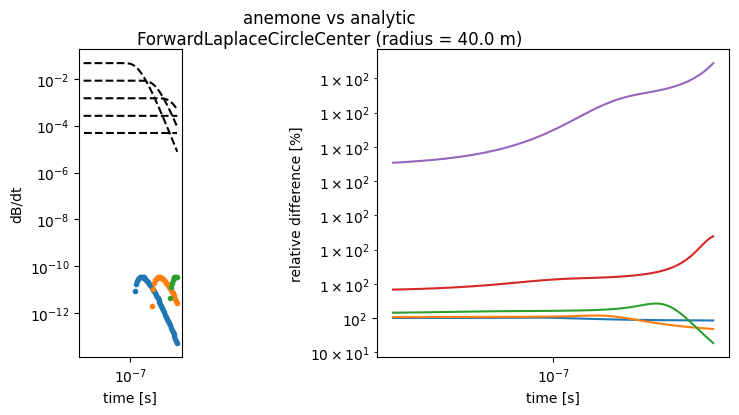

In [43]:
def calc_wavenumber_laplace(sigma, s, mu=c.mu0, epsilon=c.epsilon0, sqrt=True):
    """ get the intrinsic complex wavenumber 'k' 
        see equation 4.30 in Ward and Hohmann (pg 207)
    """
    k = -mu*(epsilon*s**2 + s*sigma)
    if sqrt: k = torch.sqrt(k)
    return k

def rte_halfspace_laplace(sigma, s, wave_length, mu=c.mu0, epsilon=c.epsilon0):
    if isinstance(mu, float):
        mu = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*mu
    if isinstance(epsilon, float):
        epsilon = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*epsilon
    
    # k2 = calc_wavenumber_laplace(sigma, s, sqrt=False)
    u = torch.sqrt(wave_length**2 + c.mu0*s*sigma)
    # u = stable_diff_root(wave_length, k)
    # rte = (1-un)/(1+un)
    rte = (wave_length - u) / (wave_length+u)
    return rte

from anemone.forwards import *

class ForwardLaplaceCircleCenter(ForwardLaplace):
    geomz = None
    t2t   = None

    def __init__(self, radius, times, waveform=None, filterfunc=None, t_end=None, tolerance=None):
        tx,rx = Loop.circle(radius), Receiver()
        super().__init__(tx, rx, times, waveform, filterfunc, t_end, tolerance)
        self.tx_radius = torch.tensor(radius, dtype=torch.double)
        self.device = times.device
        self.rte = []
        self.t2t = wv_to_t(self.times, self.t_eval, waveform=self.waveform)

    def forward(self):
        def wvlngth_integrand(wave_length):
            self.lmb = wave_length[None, :, None]
            def s_integrand(s):
                """ Hz from horizontal electric dipole. """
                self.s = s[None, None, :]
                # W = torch.sqrt(self.lmb**2 + c.mu0*(self.s*self.sigma+c.epsilon0*self.s*self.s))
                W = torch.sqrt(1. + (c.mu0*self.s*self.sigma/self.lmb**2))
                H = self.lmb+W
                R = c.mu0*self.s*self.sigma/(H*H)
                intg = R/(1+R)/self.s

                return torch.squeeze(intg).real
            res = invLaplace(s_integrand, device=self.device, n_coefficients=16)(self.t_eval)
            return (self.lmb*res).swapaxes(-2,-1)/2.
        hkl1 = Hankel(wvlngth_integrand, 1., device=self.device, smp_per_decade=16, omega_0=0.125*3.)
        hkl1._recenter_function(self.tx_radius)
        return ((hkl1.func(hkl1.lamda))@(hkl1.fc))
    
check_halfspace_circle_center(ForwardLaplaceCircleCenter, radius=40.)

In [44]:
check_halfspace_circle_center(ForwardCentralCircle, radius=3)

UnboundLocalError: local variable 'sj' referenced before assignment

In [45]:
check_halfspace_circle_center(ForwardLaplace6, radius=1.)

RuntimeError: The size of tensor a (3) must match the size of tensor b (101) at non-singleton dimension 1

In [46]:
from anemone.forwards import Forward
from anemone.physics import rte_halfspace

class ForwardExp(Forward):
    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_end=None, tolerance=None):
        super().__init__(source, receiver, times, waveform, filterfunc, t_end, tolerance, precalc=False)
    def forward(self):
        def frq_integrand(f):
            self.omega = c.twopi*f[None,:,None]
            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole. """
                self.lmb = wave_length[None, None, :]          
                # self.tmp_u0 = u0(self.omega, self.lmb)
                self.sfield_rte = torch.exp(-self.lmb*self.sfield_dz) *self.lmb/ c.fourpi
                intg = rte_halfspace(self.sigma, self.omega, self.lmb)
                intg *= self.sfield_rte
                return intg.squeeze()
            if self.geomz is None:
                hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, tolerance=self.tolerance, smp_per_decade=10, log10min=-20, log10max=20, lambda_included=True)
                def geomz_r(r):
                    return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
                Hr, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax)
                self.geomz.to(self.device)
            else:
                Hr = torch.einsum('...i,i->...', wvlngth_integrand(self.lmb.squeeze()), self.geomz)
            if self.filterfunc is not None:
                Hr *= self.filterfunc.omega_filter(self.omega.squeeze())
            if self.waveform is not None:
                Hr /= -1j*self.omega.squeeze()
            return Hr.squeeze()
        
        if self.t2t is None:
            self.cbft=invFourier(frq_integrand, device=self.device, tolerance=self.tolerance)
            def t2t_func(t_in):
                if self.t_end is not None:
                    waveform_matrix = wv_to_t(t_in, t_in, waveform=self.waveform)
                    gate_matrix = gating_matrix(t_in, self.t_st, self.t_end, n_eval=1000)
                    return gate_matrix @ waveform_matrix
                else:
                    return wv_to_t(self.times, t_in, waveform=self.waveform)

            
            Ht, self.t2t, self.omega1 = self.cbft.preintegrate(t2t_func, self.tmin, self.tmax)
            self.omega1.to(self.device)
            self.t2t.to(self.device)
        else:
            Ht = torch.einsum('ij,...j->...i', self.t2t, self.cbft.f1(self.omega1.squeeze())*self.omega1.squeeze())
        self.dpred = Ht.real
        return self.dpred

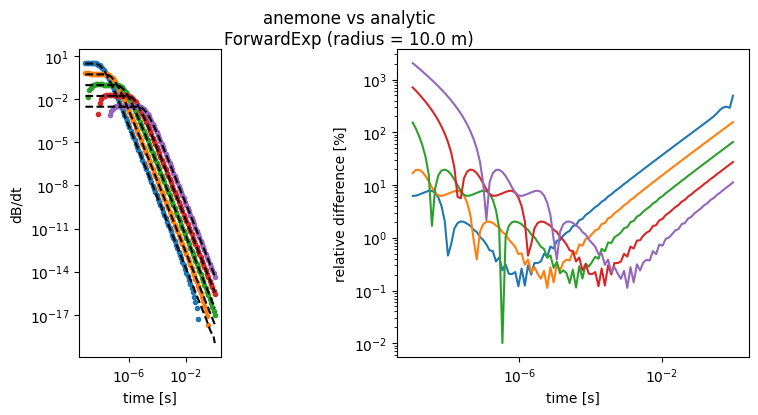

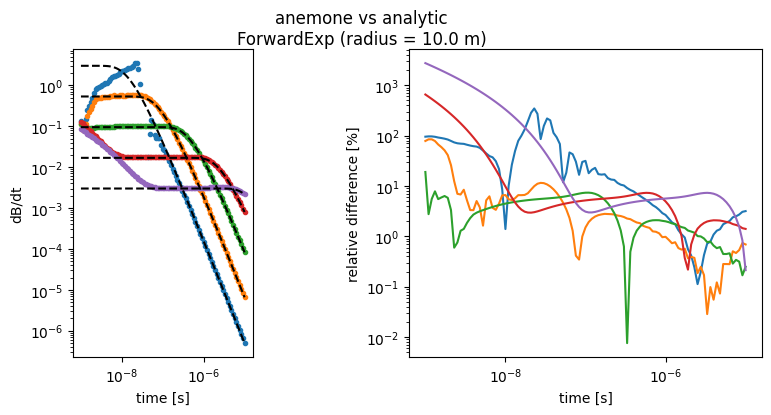

In [7]:
check_halfspace_circle_center(ForwardExp, radius=10.)

In [8]:
from anemone.forwards import Forward
from anemone.physics import rte_halfspace

class ForwardExp(Forward):
    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_end=None, tolerance=None):
        super().__init__(source, receiver, times, waveform, filterfunc, t_end, tolerance, precalc=True)
    def forward(self):
        def frq_integrand(f):
            self.omega = c.twopi*f[None,:,None]
            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole. """
                self.lmb = wave_length[None, None, :]          
                # self.tmp_u0 = u0(self.omega, self.lmb)
                self.sfield_rte = torch.exp(-self.lmb*self.sfield_dz) 
                intg = 1+rte_halfspace(self.sigma, self.omega, self.lmb)*self.sfield_rte
                return intg.squeeze() * self.lmb / c.fourpi
            if self.geomz is None:
                hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, tolerance=self.tolerance, log10min=-20, log10max=20, smp_per_decade=10)
                # hkl1.fc = hkl1.fc.real# + 0j
                # hkl1._recenter_function(torch.tensor([1e2]))
                def geomz_r(r):
                    return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
                Hr, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax)
                # self.geomz = self.geomz.to(self.device).real
            else:
                Hr = torch.einsum('...i,i->...', wvlngth_integrand(self.lmb.squeeze()), self.geomz)
            if self.filterfunc is not None:
                Hr *= self.filterfunc.omega_filter(self.omega.squeeze())
            if self.waveform is not None:
                Hr /= -1j*self.omega.squeeze()
            return Hr.squeeze()
        
        if self.t2t is None:
            self.cbft=invFourier(frq_integrand, smp_per_decade=10)
            def t2t_func(t_in):
                if self.t_end is not None:
                    waveform_matrix = wv_to_t(t_in, t_in, waveform=self.waveform)
                    gate_matrix = gating_matrix(t_in, self.t_st, self.t_end, n_eval=1000)
                    return gate_matrix @ waveform_matrix
                else:
                    return wv_to_t(self.times, t_in, waveform=self.waveform)

            
            Ht, self.t2t, self.omega1 = self.cbft.preintegrate(t2t_func, self.tmin, self.tmax)
            self.omega1 = self.omega1.to(self.device)
            self.t2t = self.t2t.to(self.device)*self.omega1.squeeze()
            self.t2t = self.t2t
        else:
            Ht = torch.einsum('ij,...j->...i', self.t2t, self.cbft.f1(self.omega1.squeeze()))
        self.dpred = Ht.real
        return self.dpred


In [9]:
class Hankel2(Hankel):
    def _recenter_function(self, r_center):
        assert self.rcidx == 0, "recentering is only allowed once"
        if isinstance(r_center, tuple): r_center = torch.sqrt(r_center[0]*r_center[1]).to(self.device)
        self.rc = r_center#.to(torch.double)
        self.rcidx = int(self.smp_per_decade*torch.log10(self.rc))
        self.rc = 10**(self.rcidx/self.smp_per_decade)
        self.lamda = self.lamda/self.rc        
        self.func_results = None

class ForwardCentralCircle(BaseForward):
    def __init__(self, radius, times, waveform=None, filterfunc=None, t_end=None, tolerance=None):
        tx,rx = Loop.circle(radius), Receiver()
        super().__init__(tx, rx, times, waveform, filterfunc, t_end, tolerance)
        self.tx_radius = torch.tensor(radius, dtype=torch.double)
        self.device = times.device
        self.rte = []
        self.t2t=None

    def forward(self):
        def f_integrand(f):
            self.omega = 2.*torch.pi*f[None, :, None]
            def wvlngth_integrand(wave_length):
                self.lmb = wave_length[None, None, :]
                self.rte=rte_halfspace(self.sigma, self.omega, self.lmb)
                intg =  self.rte
                return (1e-8 + intg)*self.lmb
            hkl1 = Hankel(wvlngth_integrand, 1, device=self.device, smp_per_decade=36, omega_0=0.125*3.)
            hkl1._recenter_function(self.tx_radius)
            return ((hkl1.func(hkl1.lamda))@(hkl1.fc+0j))

        if self.t2t is None:
            self.cbft=invFourier(f_integrand, smp_per_decade=24)
            self.cbft.fc = self.cbft.fc.real + 0j
            def t2t_func(t_in):
                return wv_to_t(self.times, t_in, waveform=self.waveform)

            
            Ht, self.t2t, self.omega1 = self.cbft.preintegrate(t2t_func, self.tmin, self.tmax)
            self.omega1 = self.omega1.to(self.device)
            self.t2t = self.t2t.to(self.device)*self.omega1.squeeze()
        else:
            Ht = torch.einsum('ij,...j->...i', self.t2t.real, self.cbft.f1(self.omega1.squeeze()).real)
        # self.dpred = Ht.real
        return Ht


Text(0.5, 0.98, 'anemone vs analytic (radius = 5.0 m)')

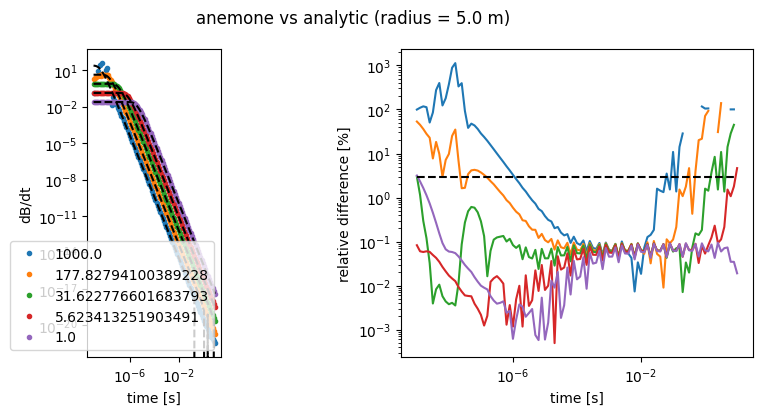

In [11]:
from anemone.experiment import Loop, Receiver
from anemone.physics import hzdt_halfspace_center_circle_loop
from anemone import constants as c
radius=5.
from anemone import constants as c

lp = Loop.square((c.pi*radius*radius)**(1/2))
rx = Receiver()

thick = torch.ones(2, dtype=torch.double)*20
times = torch.logspace(-9, 1, 101, dtype=torch.double)

rho = torch.logspace(3,0, 5, dtype=torch.double)
fwr = ForwardCentralCircle(radius, times)
dbdt = fwr(rho[None,:], thick).real.T
dbdt_analytic = hzdt_halfspace_center_circle_loop(times[:, None], rho[None,:], radius).real*c.mu0
        
import matplotlib.pyplot as plt
fig,ax = plt.subplots(1,2, sharex=True, figsize=(10,4))
ax[0].loglog(fwr.times.numpy(), dbdt.numpy(), '.')
ax[0].legend([x.item() for x in rho])
ax[0].loglog(times,      dbdt_analytic.numpy(), 'k--')
ax[0].set_ylabel('dB/dt')
ax[0].set_aspect('equal')

ax[1].loglog(times, 100*torch.abs(dbdt-dbdt_analytic)/torch.abs(dbdt_analytic))
ax[1].loglog(times, 3*torch.ones_like(times), 'k--')
ax[1].set_ylabel('relative difference [%]')
# ax[1].set_ylim(None, 1e3)
for ax_ in ax:
    ax_.set_xlabel('time [s]')

fig.suptitle(f'anemone vs analytic (radius = {radius} m)')


In [29]:
from anemone.transforms import Fourier, Hankel
class Hankel2(Hankel):
    def _recenter_function(self, r_center):
        assert self.rcidx == 0, "recentering is only allowed once"
        if isinstance(r_center, tuple): r_center = torch.sqrt(r_center[0]*r_center[1]).to(self.device)
        self.rc = r_center#.to(torch.double)
        self.rcidx = int(self.smp_per_decade*torch.log10(self.rc))#+1
        self.rc = 10**(self.rcidx/self.smp_per_decade)
        self.lamda = self.lamda/self.rc
        self.func_results = None
               

class ForwardCentralCircle(BaseForward):
    def __init__(self, radius, times, waveform=None, filterfunc=None, t_end=None, tolerance=None):
        tx,rx = Loop.circle(radius), Receiver()
        super().__init__(tx, rx, times, waveform, filterfunc, t_end, tolerance)
        self.tx_radius = torch.tensor(radius, dtype=torch.double)
        self.device = times.device
        self.rte = []
        self.t2t=None

    def forward(self):
        def f_integrand(f):
            self.omega = 2.*torch.pi*f[None, :, None]
            def wvlngth_integrand(wave_length):
                self.lmb = wave_length[None, None, :]
                self.rte=rte_halfspace2(self.sigma, self.omega, self.lmb)
                intg =  self.rte
                return 1j*intg*self.lmb
            hkl1 = Hankel2(wvlngth_integrand, 1., device=self.device, smp_per_decade=10, omega_0=0.125*3.)
            hkl1._recenter_function(self.tx_radius)
            return ((hkl1.func(hkl1.lamda))@(hkl1.fc+0j))

        if self.t2t is None:
            self.cbft=invFourier(f_integrand, smp_per_decade=24)
            def t2t_func(t_in):
                return wv_to_t(self.times, t_in, waveform=self.waveform)
            
            Ht, self.t2t, self.omega1 = self.cbft.preintegrate(t2t_func, self.tmin, self.tmax)
            self.omega1 = self.omega1.to(self.device)
            self.t2t = self.t2t.to(self.device)#.real
        else:
            Ht = torch.einsum('ij,...j->...i', self.t2t, self.cbft.f1(self.omega1.squeeze()))
        return Ht.real/4

In [48]:
from anemone.experiment import Loop, Receiver
from anemone.physics import hz_halfspace_center_circle_loop_time, hzdt_halfspace_center_circle_loop as hzdt_halfspace_center_circle_loop_time
from anemone import constants as c
radius=2

lp = Loop.square((c.pi*radius*radius)**(1/2))
rx = Receiver()

times = torch.logspace(-10, 1, 101, dtype=torch.double)

rho = torch.logspace(3,-1, 5, dtype=torch.double)
fwr = ForwardCentralCircle(radius, times)
thick = torch.tensor([1.])
dbdt = fwr(rho[None,:], thick).real.T
dbdt = fwr(rho[None,:], thick).real.T


dbdt_analytic = hz_halfspace_center_circle_loop_time(times[:, None], rho[None,:], radius).real*c.mu0
        
import matplotlib.pyplot as plt
fig,ax = plt.subplots(1,2, sharex=True, figsize=(10,4))
ax[0].loglog(fwr.times.numpy(), dbdt.numpy(), '.')
ax[0].legend([x.item() for x in rho])
ax[0].loglog(times,      dbdt_analytic.numpy(), 'k--')
ax[0].set_ylabel('dB/dt')
ax[0].set_aspect('equal')

ax[1].loglog(times, 100*torch.abs(dbdt-dbdt_analytic)/torch.abs(dbdt_analytic))
ax[1].loglog(times, 3*torch.ones_like(times), 'k--')
ax[1].set_ylabel('relative difference [%]')
# ax[1].set_ylim(None, 1e3)
for ax_ in ax:
    ax_.set_xlabel('time [s]')

fig.suptitle(f'anemone vs analytic (radius = {radius} m)')


UnboundLocalError: local variable 'sj' referenced before assignment

Text(0.5, 0.98, 'anemone vs analytic (radius = 40 m)')

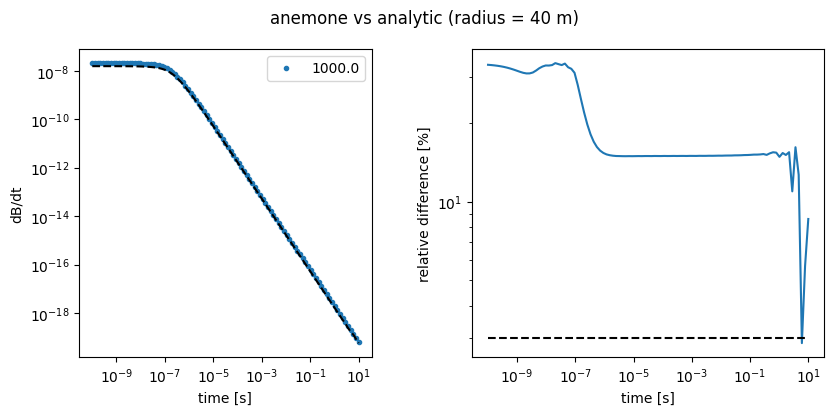

In [26]:
from anemone.experiment import Loop, Receiver
from anemone.physics import hz_halfspace_center_circle_loop_time
from anemone import constants as c
radius=40
from anemone import constants as c

lp = Loop.square((c.pi*radius*radius)**(1/2))
rx = Receiver()

times = torch.logspace(-10, 1, 101, dtype=torch.double)

rho = torch.ones(1)*1000.
fwr = ForwardCentralCircle(radius, times)
thick = torch.tensor([1.])
dbdt = fwr(rho[None,:], thick).real.squeeze()
dbdt = fwr(rho[None,:], thick).real.squeeze()


dbdt_analytic = hz_halfspace_center_circle_loop_time(times[:, None], rho[None,:], radius).real.squeeze()*c.mu0
        
import matplotlib.pyplot as plt
fig,ax = plt.subplots(1,2, sharex=True, figsize=(10,4))
ax[0].loglog(fwr.times.numpy(), dbdt.numpy(), '.')
ax[0].legend([x.item() for x in rho])
ax[0].loglog(times,      dbdt_analytic.numpy(), 'k--')
ax[0].set_ylabel('dB/dt')
ax[0].set_aspect('equal')

ax[1].loglog(times, 100*torch.abs(dbdt-dbdt_analytic)/torch.abs(dbdt_analytic))
ax[1].loglog(times, 3*torch.ones_like(times), 'k--')
ax[1].set_ylabel('relative difference [%]')
# ax[1].set_ylim(None, 1e3)
for ax_ in ax:
    ax_.set_xlabel('time [s]')

fig.suptitle(f'anemone vs analytic (radius = {radius} m)')


In [20]:
# ...existing code...
def stable_diff_root(w, k):
    """
    Compute sqrt(w**2 - k**2) with reduced risk of overflow / cancellation.
    Handles real or complex tensors.
    """
    w = torch.as_tensor(w)
    k = torch.as_tensor(k)

    # Mask where k is sufficiently smaller than w
    use_scale = torch.abs(k) <= 0.5 * torch.abs(w)

    out = torch.empty_like(w, dtype=torch.complex128 if (w.is_complex() or k.is_complex()) else w.dtype)

    # Form  w * sqrt(1 - (k/w)^2 )  (no w**2)
    if use_scale.any():
        r = k[use_scale] / w[use_scale]
        out[use_scale] = w[use_scale] * torch.sqrt(1 - r*r)

    # Form sqrt((w - k)*(w + k))
    if (~use_scale).any():
        w1 = w[~use_scale]
        k1 = k[~use_scale]
        out[~use_scale] = torch.sqrt((w1 - k1) * (w1 + k1))

    return out

def calc_wavenumber(sigma, omega, mu=c.mu0, epsilon=c.epsilon0, sqrt=True):
    """ get the intrinsic complex wavenumber 'k' 
        see equation 4.30 in Ward and Hohmann (pg 207)
    """
    k = mu*omega*(epsilon*omega - 1j*sigma)
    if sqrt: k = torch.sqrt(k)
    return k

def rte_halfspace2(sigma, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0):
    if isinstance(mu, float):
        mu = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*mu
    if isinstance(epsilon, float):
        epsilon = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*epsilon
    
    k = calc_wavenumber(sigma, omega, mu=mu, epsilon=epsilon, sqrt=True)
    un = torch.sqrt(1 - (k/wave_length)**2)
    # u = stable_diff_root(wave_length, k)
    rte = (1-un)/(1+un)
    # rte = (wave_length - u) / (wave_length+u)
    return rte

In [23]:
cRTE = rte_halfspace(1./rho[:,None,None], fwr.omega1[None,:,None], fwr.lmb[None, None,:]).squeeze()

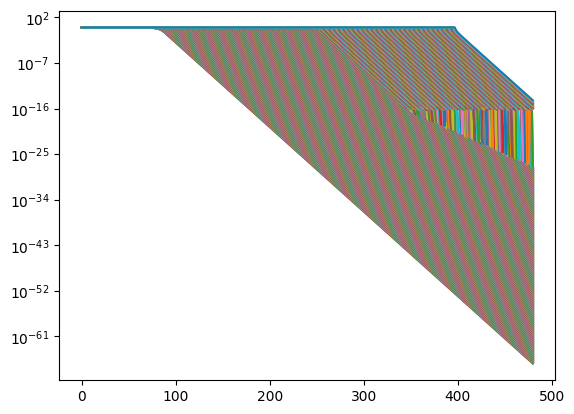

In [24]:
plt.figure()
plt.semilogy(torch.abs(cRTE.T))

In [25]:
print(fwr.omega1)

tensor([1.0000e-20, 1.1007e-20, 1.2115e-20, 1.3335e-20, 1.4678e-20, 1.6156e-20,
        1.7783e-20, 1.9573e-20, 2.1544e-20, 2.3714e-20, 2.6102e-20, 2.8730e-20,
        3.1623e-20, 3.4807e-20, 3.8312e-20, 4.2170e-20, 4.6416e-20, 5.1090e-20,
        5.6234e-20, 6.1897e-20, 6.8129e-20, 7.4989e-20, 8.2540e-20, 9.0852e-20,
        1.0000e-19, 1.1007e-19, 1.2115e-19, 1.3335e-19, 1.4678e-19, 1.6156e-19,
        1.7783e-19, 1.9573e-19, 2.1544e-19, 2.3714e-19, 2.6102e-19, 2.8730e-19,
        3.1623e-19, 3.4807e-19, 3.8312e-19, 4.2170e-19, 4.6416e-19, 5.1090e-19,
        5.6234e-19, 6.1897e-19, 6.8129e-19, 7.4989e-19, 8.2540e-19, 9.0852e-19,
        1.0000e-18, 1.1007e-18, 1.2115e-18, 1.3335e-18, 1.4678e-18, 1.6156e-18,
        1.7783e-18, 1.9573e-18, 2.1544e-18, 2.3714e-18, 2.6102e-18, 2.8730e-18,
        3.1623e-18, 3.4807e-18, 3.8312e-18, 4.2170e-18, 4.6416e-18, 5.1090e-18,
        5.6234e-18, 6.1897e-18, 6.8129e-18, 7.4989e-18, 8.2540e-18, 9.0852e-18,
        1.0000e-17, 1.1007e-17, 1.2115e-